Investigate our data_raw

In [38]:
import numpy as np
import matplotlib.pyplot as plt
import solarpy
import pvlib
import pandas as pd

In [39]:
from pathlib import Path
import sys

project_root = Path.cwd()
if project_root.name == "notebooks":
    project_root = project_root.parent

sys.path.insert(0, str(project_root))

from scripts.functions import get_dmi_ghi, resample_dmi_ghi_hourly


In [40]:
data_raw = get_dmi_ghi(
    start="2025-11-09",
    end="2026-11-09",
    station="06019",
)

data_raw.head(20)

parameterId,ghi
timestamp,
2025-11-09 00:00:00+00:00,0.0
2025-11-09 00:10:00+00:00,0.0
2025-11-09 00:20:00+00:00,0.0
2025-11-09 00:30:00+00:00,0.0
2025-11-09 00:40:00+00:00,0.0
2025-11-09 00:50:00+00:00,0.0
2025-11-09 01:00:00+00:00,0.0
2025-11-09 01:10:00+00:00,0.0
2025-11-09 01:20:00+00:00,0.0


In [41]:
data_raw.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 52498 entries, 2025-11-09 00:00:00+00:00 to 2026-11-09 00:00:00+00:00
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   ghi     52498 non-null  float64
dtypes: float64(1)
memory usage: 820.3 KB


In [42]:
data_raw.describe()

parameterId,ghi
count,52498.000000
mean,122.589622
std,213.730409
min,0.000000
25%,0.000000
50%,2.000000
75%,151.750000
max,1168.000000


Sørg for at for bsrn data check skal tidsstemplet tages for solpositionen efter 5 min for at være mere repræsentativt

In [43]:
measurement_midpoints = data_raw.index - pd.Timedelta(minutes=5)

solpos = pvlib.solarposition.get_solarposition(
    measurement_midpoints,
    latitude=56.93,
    longitude=8.6412,
    method="nrel_numpy",
)

data_raw["solar_zenith"] = solpos["zenith"].to_numpy()

### BSRN limits 

In [44]:
data_raw['dni_extra'] = pvlib.irradiance.get_extra_radiation(data_raw.index)

data_raw['ghi_extra'] = data_raw['dni_extra'] * np.cos(np.radians(data_raw['solar_zenith'])).clip(lower=0)


#Calculate flag limits for ghi using the BSRN limits
data_raw["ghi_ppl_flag"] = solarpy.quality.bsrn_limits_flag(
    data_raw["ghi"],
    data_raw["solar_zenith"],
    data_raw["dni_extra"],
    limits="ghi-ppl",
    check="upper",
)

data_raw["ghi_erl_flag"] = solarpy.quality.bsrn_limits_flag(
    data_raw["ghi"],
    data_raw["solar_zenith"],
    data_raw["dni_extra"],
    limits="ghi-erl",
    check="upper",
)

In [45]:
data_raw[["ghi", "ghi_ppl_flag", "ghi_erl_flag"]].head(20)

parameterId,ghi,ghi_ppl_flag,ghi_erl_flag
timestamp,,,
2025-11-09 00:00:00+00:00,0.0,False,False
2025-11-09 00:10:00+00:00,0.0,False,False
2025-11-09 00:20:00+00:00,0.0,False,False
2025-11-09 00:30:00+00:00,0.0,False,False
2025-11-09 00:40:00+00:00,0.0,False,False
2025-11-09 00:50:00+00:00,0.0,False,False
2025-11-09 01:00:00+00:00,0.0,False,False
2025-11-09 01:10:00+00:00,0.0,False,False
2025-11-09 01:20:00+00:00,0.0,False,False


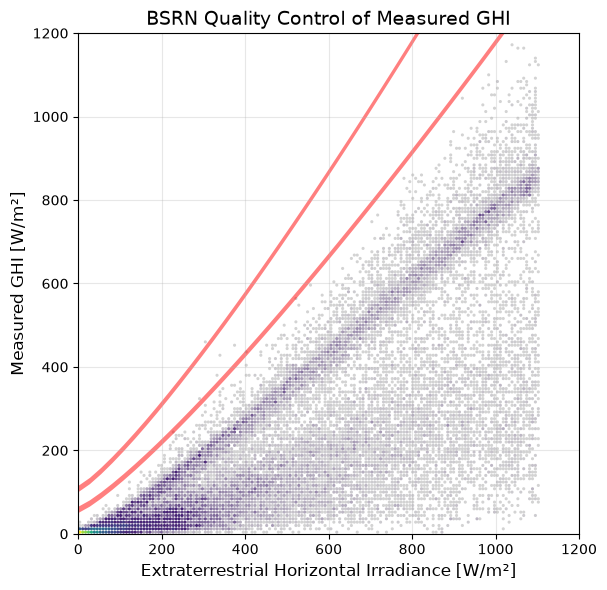

In [56]:
#Plot the data and the BSRN limits
fig, ax = solarpy.plotting.plot_bsrn_limits(
    irradiance=data_raw["ghi"],
    component="ghi",
    ghi_extra=data_raw["ghi_extra"],
)
fig.set_size_inches(12, 6)
ax.set_title("BSRN Quality Control of Measured GHI", fontsize=14)
ax.set_xlabel("Extraterrestrial Horizontal Irradiance [W/m²]", fontsize=12)
ax.set_ylabel("Measured GHI [W/m²]", fontsize=12)
ax.tick_params(axis="both", labelsize=10)
ax.grid(alpha=0.3)
ax.set_xlim(0, 1200)
ax.set_ylim(0, 1200)
ax.set_aspect("equal", adjustable="box")
plt.tight_layout()
plt.show()

Control check, to see how many options that has been marked:

In [57]:
_, data_raw["ghi_ppl_upper"] = solarpy.quality.bsrn_limits(
    data_raw["solar_zenith"], data_raw["dni_extra"], limits="ghi-ppl"
)

_, data_raw["ghi_erl_upper"] = solarpy.quality.bsrn_limits(
    data_raw["solar_zenith"], data_raw["dni_extra"], limits="ghi-erl"
)

# Over ERL, men stadig inden for PPL
erl_only = data_raw.loc[
    (data_raw["ghi"] > data_raw["ghi_erl_upper"])
    & (data_raw["ghi"] <= data_raw["ghi_ppl_upper"]),
    ["ghi", "ghi_erl_upper", "ghi_ppl_upper", "solar_zenith"],
]

# Over PPL: uden for den fysisk mulige grænse
above_ppl = data_raw.loc[
    data_raw["ghi"] > data_raw["ghi_ppl_upper"],
    ["ghi", "ghi_ppl_upper", "ghi_erl_upper", "solar_zenith"],
]

print("Number of measurements above the ERL limit but within PPL:", len(erl_only))
print("Number of measurements above the PPL limit:", len(above_ppl))

display(erl_only)
display(above_ppl)

Number of measurements above the ERL limit but within PPL: 6
Number of measurements above the PPL limit: 1


parameterId,ghi,ghi_erl_upper,ghi_ppl_upper,solar_zenith
timestamp,,,,
2025-11-16 10:30:00+00:00,383.0,345.938944,469.923680,76.373352
2025-11-16 11:10:00+00:00,427.0,360.730456,488.413070,75.796485
2025-11-19 12:30:00+00:00,327.0,302.985066,416.231333,78.082339
2026-09-16 06:20:00+00:00,241.0,239.123706,336.404633,80.394630
2026-09-16 07:20:00+00:00,438.0,431.394122,576.742652,72.580080
2026-10-10 08:10:00+00:00,453.0,395.890969,532.363711,74.169914


parameterId,ghi,ghi_ppl_upper,ghi_erl_upper,solar_zenith
timestamp,,,,
2025-11-19 10:20:00+00:00,457.0,438.065315,320.452252,77.389569


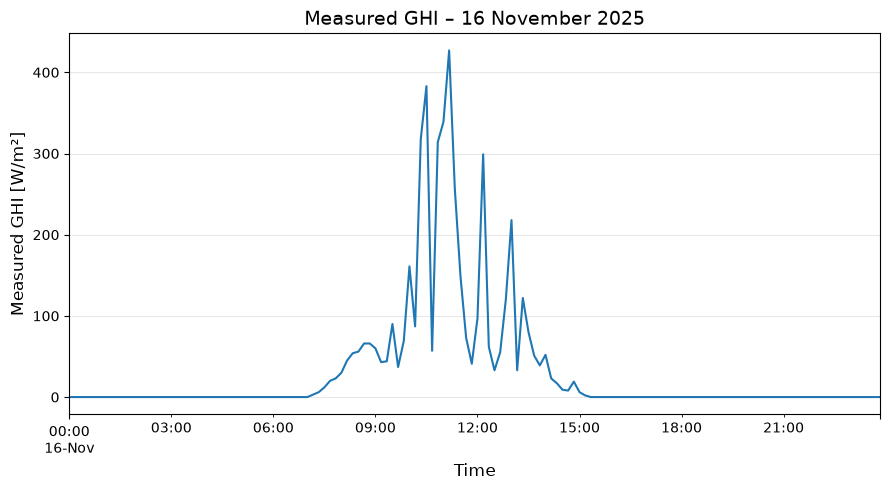

In [59]:
error_data = data_raw.loc["2025-11-16"]

fig, ax = plt.subplots(figsize=(9, 5))

error_data["ghi"].plot(ax=ax)

ax.set_title("Measured GHI – 16 November 2025", fontsize=14)
ax.set_xlabel("Time", fontsize=12)
ax.set_ylabel("Measured GHI [W/m²]", fontsize=12)

ax.tick_params(axis="both", labelsize=10)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#display(error_data)

Convert from 10 min resolution to 1 hour with righ closed columns

In [64]:
#Resample 10-minute measurements to hourly values
data_hourly = resample_dmi_ghi_hourly(data_raw)

data_hourly.head(10)

,ghi_measured,n_observations
timestamp,,
2025-11-09 00:00:00+00:00,NaN,1
2025-11-09 01:00:00+00:00,0.000000,6
2025-11-09 02:00:00+00:00,0.000000,6
2025-11-09 03:00:00+00:00,0.000000,6
2025-11-09 04:00:00+00:00,0.000000,6
2025-11-09 05:00:00+00:00,0.000000,6
2025-11-09 06:00:00+00:00,0.000000,6
2025-11-09 07:00:00+00:00,0.500000,6
2025-11-09 08:00:00+00:00,10.500000,6


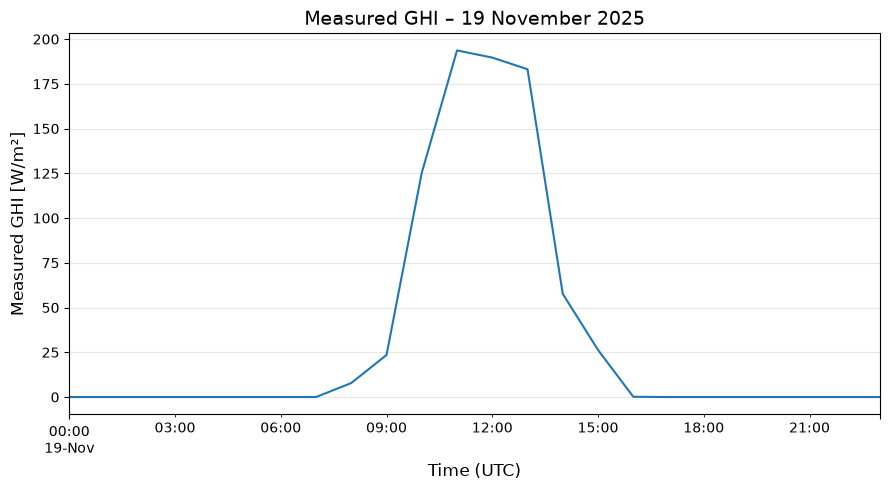

In [65]:
error_data1 = data_hourly.loc["2025-11-19"]

fig, ax = plt.subplots(figsize=(9, 5))

error_data1["ghi_measured"].plot(ax=ax)

ax.set_title("Measured GHI – 19 November 2025", fontsize=14)
ax.set_xlabel("Time (UTC)", fontsize=12)
ax.set_ylabel("Measured GHI [W/m²]", fontsize=12)

ax.tick_params(axis="both", labelsize=10)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

#display(error_data1)

### Generate plots 

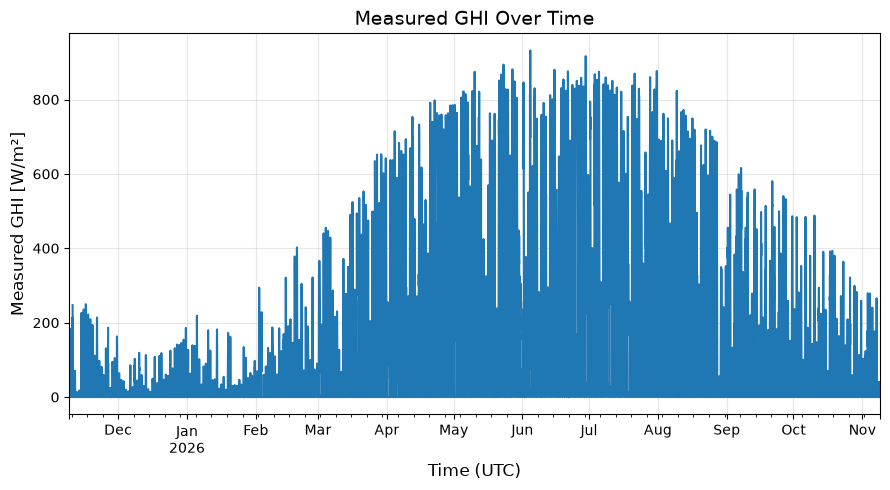

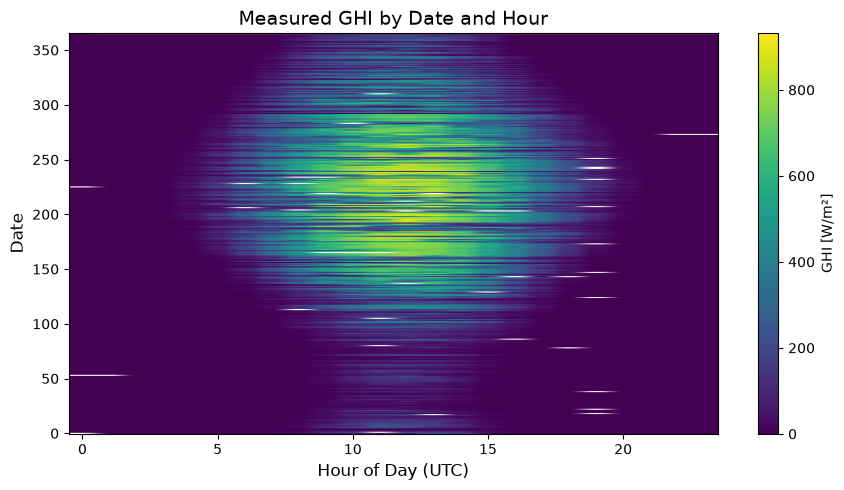

In [66]:
ghi = data_hourly["ghi_measured"].sort_index()

#Time series
fig, ax = plt.subplots(figsize=(9, 5))

ghi.plot(ax=ax)

ax.set_title("Measured GHI Over Time", fontsize=14)
ax.set_xlabel("Time (UTC)", fontsize=12)
ax.set_ylabel("Measured GHI [W/m²]", fontsize=12)

ax.tick_params(axis="both", labelsize=10)
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


#Heatmap: date vs. hour of day (UTC)
heatmap_data = ghi.to_frame("ghi")
heatmap_data["date"] = heatmap_data.index.date
heatmap_data["hour"] = heatmap_data.index.hour

heatmap = heatmap_data.pivot(index="date",columns="hour",values="ghi")

fig, ax = plt.subplots(figsize=(9, 5))

im = ax.imshow(heatmap, aspect="auto", origin="lower")

ax.set_title("Measured GHI by Date and Hour", fontsize=14)
ax.set_xlabel("Hour of Day (UTC)", fontsize=12)
ax.set_ylabel("Date", fontsize=12)

ax.tick_params(axis="both", labelsize=10)

fig.colorbar(im, ax=ax, label="GHI [W/m²]")

plt.tight_layout()
plt.show()

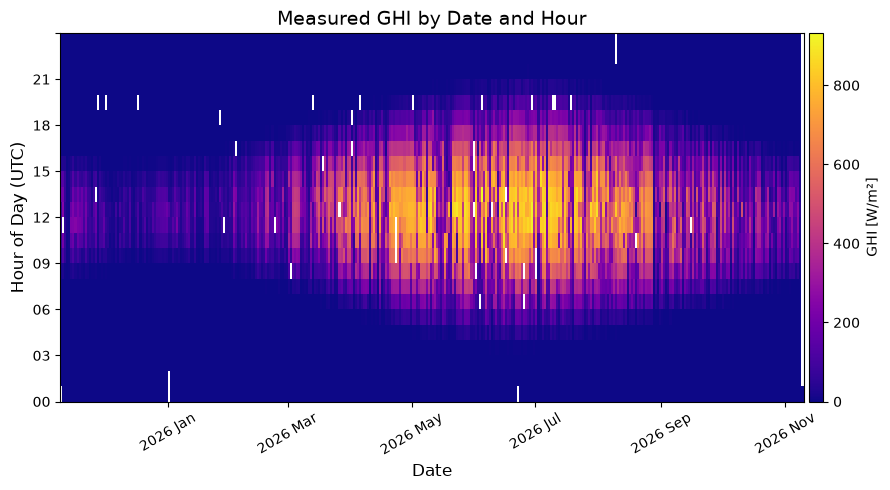

In [69]:
#Intraday heatmap of measured GHI
fig, ax = solarpy.plotting.plot_intraday_heatmap(
    time=data_hourly.index,
    values=data_hourly["ghi_measured"],
    time_resolution=60,
    cmap="plasma",
    colorbar_label="GHI [W/m²]"
)

fig.set_size_inches(9, 5)

ax.set_title("Measured GHI by Date and Hour", fontsize=14)
ax.set_xlabel("Date", fontsize=12)
ax.set_ylabel("Hour of Day (UTC)", fontsize=12)

ax.tick_params(axis="both", labelsize=10)

plt.tight_layout()
plt.show()